In [4]:
import struct
import numpy as np
import matplotlib.pyplot as plt

def read_images(file_name):
    f = open(file_name, 'rb')
    _, n, rows, cols = struct.unpack('>IIII', f.read(16))
    imgs = np.frombuffer(f.read(), dtype=np.uint8)
    f.close()
    return imgs.reshape(n, rows * cols).astype(np.float32) / 255

def read_labels(file_name):
    f = open(file_name, 'rb')
    _, n = struct.unpack('>II', f.read(8))
    labels = np.frombuffer(f.read(), dtype=np.uint8)
    f.close()
    return labels

X_train_raw = read_images('train-images.idx3-ubyte')
y_train_raw = read_labels('train-labels.idx1-ubyte')
X_test_raw = read_images('t10k-images.idx3-ubyte')
y_test_raw = read_labels('t10k-labels.idx1-ubyte')

### Assignment 1 (4 scores):

- Use Numpy only to construct the Logistic Regression model.
- Train and evaluating (precision, recall, f1) the Logistic Regression model using the Gradient Descent approach **to classify 0 and 1 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [5]:
def binary_scores(actual, guess):
    tp = np.sum((actual == 1) & (guess == 1))
    fp = np.sum((actual == 0) & (guess == 1))
    fn = np.sum((actual == 1) & (guess == 0))

    p = tp / (tp + fp + 1e-8)
    r = tp / (tp + fn + 1e-8)
    f = 2 * p * r / (p + r + 1e-8)
    return p, r, f

Precision: 0.9982
Recall: 1.0
F1-Score: 0.9991


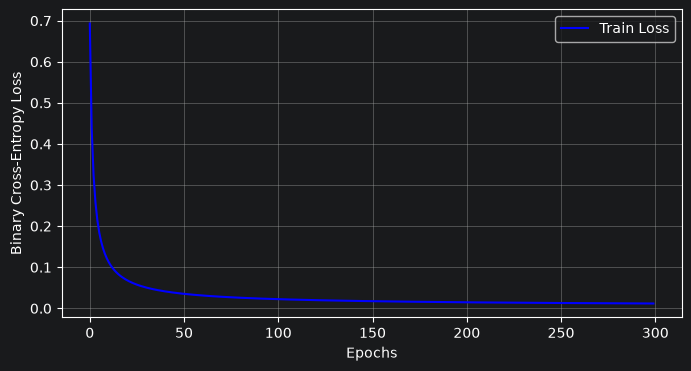

In [6]:
train_mask = (y_train_raw == 0) | (y_train_raw == 1)
test_mask = (y_test_raw == 0) | (y_test_raw == 1)

X_train_bin = X_train_raw[train_mask]
y_train_bin = y_train_raw[train_mask].astype(np.float32).reshape(-1, 1)
X_test_bin = X_test_raw[test_mask]
y_test_bin = y_test_raw[test_mask]

w = np.zeros((X_train_bin.shape[1], 1))
b = 0.0
losses = []
rate = 0.1

for i in range(300):
    z = X_train_bin @ w + b
    y_hat = 1 / (1 + np.exp(-np.clip(z, -100, 100)))
    loss = -np.mean(y_train_bin * np.log(y_hat + 1e-10) + (1 - y_train_bin) * np.log(1 - y_hat + 1e-10))
    losses.append(loss)
    w = w - rate * (X_train_bin.T @ (y_hat - y_train_bin)) / len(y_train_bin)
    b = b - rate * np.mean(y_hat - y_train_bin)

z_test = X_test_bin @ w + b
y_pred_bin = (1 / (1 + np.exp(-np.clip(z_test, -100, 100))) >= 0.5).astype(int).flatten()
p, r, f1 = binary_scores(y_test_bin, y_pred_bin)

print("Precision:", round(p, 4))
print("Recall:", round(r, 4))
print("F1-Score:", round(f1, 4))

plt.figure(figsize=(8, 4))
plt.plot(losses, color='blue', label='Train Loss')
plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()

### Assignment 2 (4 scores):

- Use Numpy only to construct the Softmax Regression model.
- Train and evaluating (precision, recall, f1) the Softmax Regression model using the Gradient Descent approach **to classify 10 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [7]:
def one_hot(y):
    result = np.zeros((len(y), 10))
    result[np.arange(len(y)), y] = 1
    return result


def multiclass_scores(actual, guess):
    p_list = []
    r_list = []
    f_list = []

    for digit in range(10):
        tp = np.sum((actual == digit) & (guess == digit))
        fp = np.sum((actual != digit) & (guess == digit))
        fn = np.sum((actual == digit) & (guess != digit))
        p = tp / (tp + fp + 1e-8)
        r = tp / (tp + fn + 1e-8)
        f = 2 * p * r / (p + r + 1e-8)
        p_list.append(p)
        r_list.append(r)
        f_list.append(f)

    return np.mean(p_list), np.mean(r_list), np.mean(f_list)

Macro Precision: 0.9135
Macro Recall: 0.9133
Macro F1-Score: 0.9132


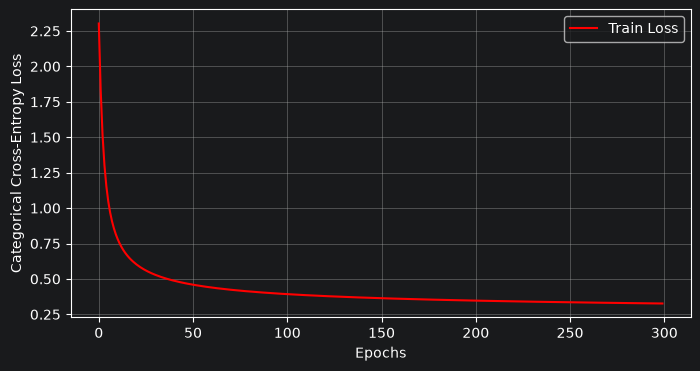

In [8]:
W = np.zeros((X_train_raw.shape[1], 10))
b_multi = np.zeros((1, 10))
y_hot = one_hot(y_train_raw)
losses_multi = []
rate = 0.5

for i in range(300):
    scores = X_train_raw @ W + b_multi
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    loss = -np.mean(np.sum(y_hot * np.log(probs + 1e-10), axis=1))
    losses_multi.append(loss)
    diff = (probs - y_hot) / len(y_train_raw)
    W = W - rate * (X_train_raw.T @ diff)
    b_multi = b_multi - rate * np.sum(diff, axis=0, keepdims=True)

scores_test = X_test_raw @ W + b_multi
exp_test = np.exp(scores_test - np.max(scores_test, axis=1, keepdims=True))
probs_test = exp_test / np.sum(exp_test, axis=1, keepdims=True)
y_pred_multi = np.argmax(probs_test, axis=1)
p_m, r_m, f1_m = multiclass_scores(y_test_raw, y_pred_multi)

print("Macro Precision:", round(p_m, 4))
print("Macro Recall:", round(r_m, 4))
print("Macro F1-Score:", round(f1_m, 4))

plt.figure(figsize=(8, 4))
plt.plot(losses_multi, color='red', label='Train Loss')
plt.xlabel('Epochs')
plt.ylabel('Categorical Cross-Entropy Loss')
plt.legend()
plt.grid(True)
plt.show()

### Assignment 3 (2 scores):

- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Logistic Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Softmax Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

model1 = LogisticRegression(solver='lbfgs', max_iter=500)
model1.fit(X_train_bin, y_train_bin.flatten())
pred1 = model1.predict(X_test_bin)

p1 = precision_score(y_test_bin, pred1)
r1 = recall_score(y_test_bin, pred1)
f1_1 = f1_score(y_test_bin, pred1)
print("Scikit-Learn Logistic Regression")
print("Precision:", round(p1, 4))
print("Recall:", round(r1, 4))
print("F1-Score:", round(f1_1, 4))

model2 = LogisticRegression(solver='lbfgs', max_iter=500)
model2.fit(X_train_raw, y_train_raw)
pred2 = model2.predict(X_test_raw)

p2 = precision_score(y_test_raw, pred2, average='macro')
r2 = recall_score(y_test_raw, pred2, average='macro')
f2 = f1_score(y_test_raw, pred2, average='macro')
print("Scikit-Learn Softmax Regression")
print("Macro Precision:", round(p2, 4))
print("Macro Recall:", round(r2, 4))
print("Macro F1-Score:", round(f2, 4))

Scikit-Learn Logistic Regression
Precision: 0.9991
Recall: 1.0
F1-Score: 0.9996
Scikit-Learn Softmax Regression
Macro Precision: 0.9248
Macro Recall: 0.9247
Macro F1-Score: 0.9247
